In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd

# Upload file dulu di panel kiri (folder)
df = pd.read_csv('data_mahasiswa.csv')

# Lihat data
df.head()

,NIM,IPK,Kehadiran,Nilai,Status
0,1,3.45,88,84,Lulus
1,2,2.10,60,65,Tidak
2,3,3.20,82,78,Lulus
3,4,3.80,95,90,Lulus
4,5,2.50,70,72,Tidak


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   NIM        30 non-null     int64  
 1   IPK        30 non-null     float64
 2   Kehadiran  30 non-null     int64  
 3   Nilai      30 non-null     int64  
 4   Status     30 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 1.3+ KB


,NIM,IPK,Kehadiran,Nilai
count,30.000000,30.000000,30.000000,30.000000
mean,15.500000,2.989333,78.533333,77.433333
std,8.803408,0.616301,12.420043,9.736824
min,1.000000,1.900000,52.000000,59.000000
25%,8.250000,2.512500,70.500000,71.250000
50%,15.500000,3.125000,81.500000,77.500000
75%,22.750000,3.437500,87.750000,84.750000
max,30.000000,3.900000,96.000000,93.000000


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Status'] = le.fit_transform(df['Status'])  # Lulus=1, Tidak=0

In [ ]:
from sklearn.model_selection import train_test_split

X = df[['IPK','Kehadiran','Nilai']]
y = df['Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("=== HASIL KLASIFIKASI ===")
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

=== HASIL KLASIFIKASI ===
Akurasi: 1.0
Confusion Matrix:
 [[5 0]
 [0 1]]


In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(X)

df.head()

,NIM,IPK,Kehadiran,Nilai,Status,Cluster
0,1,3.45,88,84,0,2
1,2,2.10,60,65,1,0
2,3,3.20,82,78,0,1
3,4,3.80,95,90,0,2
4,5,2.50,70,72,1,0


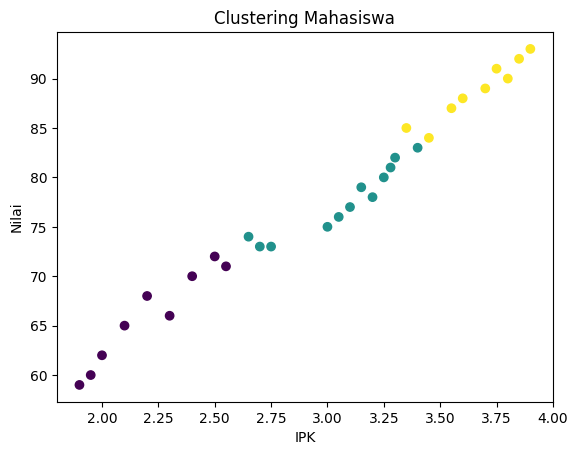

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df['IPK'], df['Nilai'], c=df['Cluster'])
plt.xlabel('IPK')
plt.ylabel('Nilai')
plt.title('Clustering Mahasiswa')
plt.show()

In [ ]:
df['Cluster'].value_counts()

,count
Cluster,
1,12
2,9
0,9
